# HealthAware final CatBoost engine
Deliverable 3 uses NHANES 2021-2023 and eleven non-invasive inputs to estimate three survey-derived glycemic categories. HealthAware is a screening and awareness prototype. Clinical diagnosis requires appropriate clinical testing.

The supplied [dataset and evaluation README](README.md) documents the reference configuration. The benchmark reported there and the results recomputed below are identified separately.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from catboost import CatBoostClassifier
from sklearn.metrics import (
    ConfusionMatrixDisplay, accuracy_score, classification_report, confusion_matrix, f1_score,
)
from sklearn.model_selection import train_test_split

DATA = Path("data/nhanes_diabetes_2021_2023.csv")
TARGET = "glycemic_status"
CLASSES = [0, 1, 2]
NAMES = ["Normal", "Prediabetes", "Diabetes"]
FEATURES = [
    "age_years", "sex", "bmi_kg_m2", "hypertension_diagnosed",
    "high_cholesterol_diagnosed", "stroke", "heart_disease_or_attack",
    "meets_activity_guidelines", "smoking_status", "heavy_alcohol_use", "general_health_label",
]
CATEGORICAL = ["sex", "smoking_status", "general_health_label"]
raw = pd.read_csv(DATA)
assert len(raw) == 6001 and raw.participant_id.is_unique
assert len(FEATURES) == 11 and TARGET not in FEATURES
assert set(raw[TARGET]) == set(CLASSES)
print(f"{len(raw):,} participants, {len(FEATURES)} model inputs")
print(raw[TARGET].value_counts().sort_index().rename(index=dict(zip(CLASSES, NAMES))))

6,001 participants, 11 model inputs
glycemic_status
Normal         2640
Prediabetes    2308
Diabetes       1053
Name: count, dtype: int64


## Features, preprocessing and split

The explicit feature list excludes participant IDs, survey weights, laboratory measurements and diabetes label proxies. Use CatBoost's native categorical encoding. Missing categories receive a fixed string token; numeric missing values are supported natively. There is no learned preprocessing outside CatBoost.

First reserve 1,201 test rows using seed 2026. Split the remaining 4,800 rows using seed 2027 and a 25% validation fraction. Both operations stratify on the target. The input file has one row per participant.

In [2]:
x = raw.loc[:, FEATURES].copy()
y = raw[TARGET].astype(int)
for name in CATEGORICAL:
    x[name] = x[name].fillna("__MISSING__").astype(str)
for name in set(FEATURES) - set(CATEGORICAL):
    x[name] = pd.to_numeric(x[name], errors="raise")
development, test = train_test_split(
    np.arange(len(raw)), test_size=1201, stratify=y, random_state=2026,
)
train, validation = train_test_split(
    development, test_size=.25, stratify=y.iloc[development], random_state=2027,
)
assert (len(train), len(validation), len(test)) == (3600, 1200, 1201)
ids = [set(raw.participant_id.iloc[part]) for part in (train, validation, test)]
assert not (ids[0] & ids[1] or ids[1] & ids[2] or ids[0] & ids[2])
print(pd.DataFrame({
    role: y.iloc[part].value_counts().reindex(CLASSES)
    for role, part in [("Train", train), ("Validation", validation), ("Test", test)]
}).rename(index=dict(zip(CLASSES, NAMES))))
print("\nTraining input types and missing values in source")
print(pd.DataFrame({"type": x.dtypes, "missing": raw.iloc[train][FEATURES].isna().sum()}))
print("\nTraining numeric summary")
print(x.iloc[train].describe().round(2))

                 Train  Validation  Test
glycemic_status                         
Normal            1584         528   528
Prediabetes       1385         461   462
Diabetes           631         211   211

Training input types and missing values in source
                               type  missing
age_years                     int64        0
sex                             str        0
bmi_kg_m2                   float64       51
hypertension_diagnosed      float64        2
high_cholesterol_diagnosed  float64       24
stroke                      float64      138
heart_disease_or_attack     float64      151
meets_activity_guidelines   float64       45
smoking_status                  str        5
heavy_alcohol_use           float64       24
general_health_label            str        2

Training numeric summary
       age_years  bmi_kg_m2  ...  meets_activity_guidelines  heavy_alcohol_use
count    3600.00    3549.00  ...                    3555.00            3576.00
mean       52.58    

## Train with validation-only early stopping

Class weights are listed in target-code order. CatBoost uses multiclass log loss for early stopping and retains its best validation iteration. Reported test metrics use the original test labels without sample weighting.

In [3]:
CONFIG = dict(
    iterations=1000, depth=5, learning_rate=.03, l2_leaf_reg=8,
    class_weights=[.5, 1.2, 2.5], random_seed=2026, early_stopping_rounds=100,
)
model = CatBoostClassifier(
    **CONFIG, loss_function="MultiClass", eval_metric="MultiClass",
    cat_features=CATEGORICAL, allow_writing_files=False, thread_count=4, verbose=False,
)
model.fit(x.iloc[train], y.iloc[train], eval_set=(x.iloc[validation], y.iloc[validation]),
          use_best_model=True)
print("Trees retained", model.tree_count_)
print("Best validation multiclass log loss", model.get_best_score()["validation"]["MultiClass"])

Trees retained 296
Best validation multiclass log loss 0.8607764679583846


## Held-out test evaluation

              precision    recall  f1-score   support

      Normal     0.8009    0.3352    0.4726       528
 Prediabetes     0.4298    0.5628    0.4873       462
    Diabetes     0.3840    0.6825    0.4915       211

    accuracy                         0.4838      1201
   macro avg     0.5382    0.5268    0.4838      1201
weighted avg     0.5849    0.4838    0.4816      1201

Accuracy 48.3764% | Macro F1 48.3815% | Weighted F1 48.1601%
Diabetes classified as Normal: 2/211


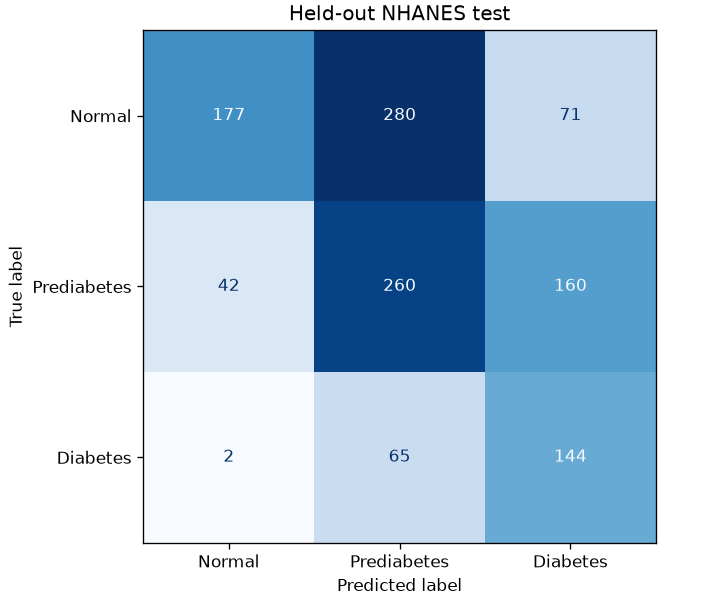

In [4]:
actual = y.iloc[test]
predicted = np.asarray(model.predict(x.iloc[test]), dtype=int).ravel()
accuracy = accuracy_score(actual, predicted)
macro = f1_score(actual, predicted, labels=CLASSES, average="macro")
weighted = f1_score(actual, predicted, labels=CLASSES, average="weighted")
matrix = confusion_matrix(actual, predicted, labels=CLASSES)
print(classification_report(actual, predicted, labels=CLASSES, target_names=NAMES,
                            digits=4, zero_division=0))
print(f"Accuracy {accuracy:.4%} | Macro F1 {macro:.4%} | Weighted F1 {weighted:.4%}")
print(f"Diabetes classified as Normal: {matrix[2, 0]}/{matrix[2].sum()}")
fig, ax = plt.subplots(figsize=(6, 5), layout="constrained")
ConfusionMatrixDisplay(matrix, display_labels=NAMES).plot(ax=ax, cmap="Blues", colorbar=False)
ax.set_title("Held-out NHANES test")
plt.show()

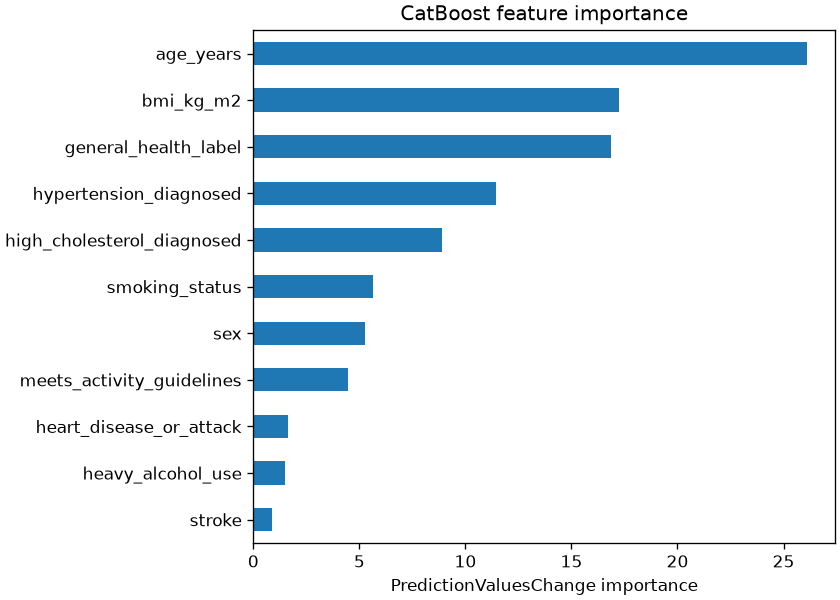

In [5]:
importance = pd.Series(model.get_feature_importance(), index=FEATURES).sort_values()
fig, ax = plt.subplots(figsize=(7, 5), layout="constrained")
importance.plot.barh(ax=ax)
ax.set(xlabel="PredictionValuesChange importance", title="CatBoost feature importance")
plt.show()

## Interpretation and limitations

The confusion matrix shows how often the engine detects elevated-risk categories and how often it assigns them to a neighbouring category. Feature importance reports how inputs contribute to this fitted model's predictions. The study uses a US survey cohort, and the test is an internal holdout. Results do not establish calibration, transferability to Kenya or clinical diagnostic performance.

## Reproduction record

| Held-out metric | Supplied README | This executed notebook |
|---|---:|---:|
| Accuracy | 47.21% | 48.38% |
| Macro F1 | 47.24% | 48.38% |
| Weighted F1 | 47.14% | 48.16% |
| Prediabetes recall | 54.11% | 56.28% |
| Diabetes recall | 66.35% | 68.25% |

The notebook retained 296 trees. It correctly classified 144 of 211 diabetes labels and assigned 2 of the 211 to Normal. Age, BMI and general health were the three highest-importance inputs in this run. The supplied reference README is preserved verbatim.

The archive gives split sizes and seeds, but lacks row membership, original encoding code and library versions. With the same sizes and seeds, a train-first split would share only 610 of the 1,201 test rows with the test-first split implemented here. This comparison inspected membership only, without fitting or scoring another model. Split order and encoding are possible sources of the difference. The original source run would be needed to identify the exact cause.

Run from the repository root in a Python environment with CatBoost, scikit-learn, pandas, NumPy and matplotlib. Verified library versions were CatBoost 1.2.10, scikit-learn 1.9.1, pandas 3.1.0, NumPy 2.5.4 and matplotlib 3.11.2.
